In [1]:
import numpy as np
import matplotlib.pyplot as plt
import dipole

In [2]:
def Ff(r, Qs2, gamma, ec, p):
        ''' Returns function F(r) for parameters (Qs2, ec, p, gamma) '''
        
        print(f"Calculating F(r) for parameters: Qs2 = {Qs2}, ec = {ec}, p = {p}, gamma = {gamma}")
        lambda_qcd = 0.241
        exponent = (((r**2 * Qs2) ** gamma)/4 * np.log( (1/(r*lambda_qcd)) + np.exp(1)*ec ) )** p
        
        return 1 - np.exp(-exponent) ** (1/p)

Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameters: Qs2 = 0.09047048, ec = 1.000033, p = 1.000014, gamma = 1.603242
Calculating F(r) for parameter

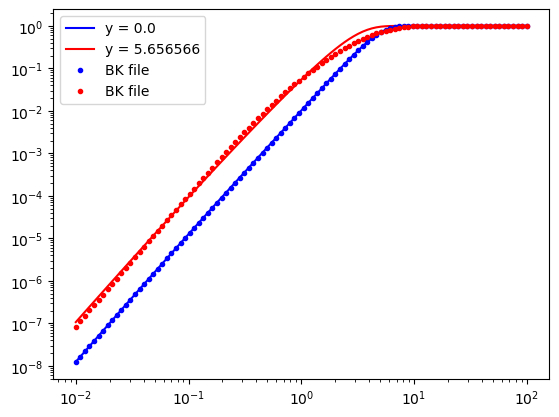

In [6]:
file = "../data/NLO/pd/MAP/funcformvsy_0.dat"
y, Qs2, gamma, ec, p = np.loadtxt(file, unpack=True)

rs = np.logspace(-2, 2, 100)
N = []
for r in rs:
    N.append(Ff(r, Qs2[0], gamma[0], ec[0], p[0]))

N2= []
i = 70
for r in rs:
    N2.append(Ff(r, Qs2[i], gamma[i], ec[i], p[i]))


bk_file = "/home/caaucasu/sidis_fit/data/NLO/pd/MAP/0.dat"
interpolator = dipole.BKDipole(bk_file)
Nyr = lambda yy, rr: interpolator.ln_Nr(yy, rr)

plt.plot(rs, N, label=f'y = {y[0]}', color = 'b')
plt.plot(rs, N2, label=f'y = {y[i]}', color = 'r')
plt.plot(rs, np.exp(Nyr(y[0], rs)), '.', label=f'BK file', color = 'b')
plt.plot(rs, np.exp(Nyr(y[i], rs)), '.', label=f'BK file', color = 'r')
plt.legend()
plt.xscale('log')
plt.yscale('log')